# Versión 003: selección exclusivamente por F1 macro

El usuario reportó un puntaje público de 0,73888 para la versión 002 y pidió usar exclusivamente F1 macro. La captura muestra el puntaje, pero no el nombre de la métrica del concurso. Se registra el valor como evidencia aportada por el usuario, sin asumir que verifica por sí solo la fórmula del leaderboard. La meta solicitada se interpreta como F1 macro 0,90 (90%), no como una garantía.

## Qué cambia y por qué
Una bolsa global de palabras no distingue bien el papel de cada valoración en una reseña con sentimientos mixtos. Comparamos una representación de palabras y caracteres con representaciones que distinguen tercios del texto y posiciones de las oraciones desde ambos extremos. Una variante segmenta cláusulas por conectores y distingue cierres discursivos como «en fin» o «cada quien», sin asignar una polaridad a esos marcadores. Otra variante añade interacciones entre los n-gramas y las primeras dos o tres palabras de la última oración; son rasgos observables, sin polaridad impuesta ni etiquetas externas. El clasificador aprende sus pesos. No existe una regla que asigne la clase de la última oración.

Se normalizan acentos en esta versión para compartir evidencia entre variantes ortográficas; no se eliminan negaciones ni palabras vacías. Los caracteres permiten compartir fragmentos entre palabras y tolerar algunos errores tipográficos. Las nuevas representaciones aumentan capacidad, por lo que se usan frecuencia mínima, límites de vocabulario y regularización. Todos los vocabularios e IDF se aprenden dentro del entrenamiento de cada Pipeline.

## Protocolo fijado antes de ejecutar
Nueve configuraciones: cuatro representaciones con dos valores de C y la referencia 002. Se elige por F1 macro; entre resultados a 0,003 del máximo se prefiere menor brecha de F1 entrenamiento-validación. La brecha no se minimiza sola, pues eso puede favorecer subajuste.

Se usa solo el desarrollo anterior: 9600 filas. La antigua prueba local permanece excluida. La CV anidada usa tres folds externos y tres internos; cada fold externo repite la selección únicamente dentro de su entrenamiento. Se reporta además el 002 sobre exactamente los mismos folds externos.

**Límite:** desarrollo ya fue usado en experimentos anteriores y se leyeron ejemplos para diseñar las características. La CV anidada protege la separación de ajuste y selección dentro de cada fold, pero no convierte estos datos en una prueba externa virgen. No se deben reutilizar los resultados de la prueba anterior como métricas de este modelo.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
if not Path('reports/registro_experimento_003.json').exists(): os.chdir('..')
r=json.loads(Path('reports/registro_experimento_003.json').read_text())
cv=pd.read_csv('reports/resultados_cv_003.csv')
display(cv[['params','mean_train_score','mean_test_score','std_test_score','f1_gap','selected']])
display(Markdown('**Configuración elegida:** '+r['selected_params']))
comparison=pd.DataFrame({'medida':['F1 macro CV selección','F1 macro OOF anidada 003','F1 macro OOF anidada referencia 002'], 'valor':[r['selected_cv_f1_macro'],r['nested_f1_macro_oof'],r['nested_baseline002_f1_macro_oof']]})
display(comparison)
display(pd.read_csv('reports/cv_003_anidada.csv'))
display(Markdown(f"F1 macro externo, media ± desviación entre folds: **{r['nested_f1_macro_fold_mean']:.5f} ± {r['nested_f1_macro_fold_std']:.5f}**. F1 macro OOF agrupa todas las predicciones externas y puede diferir de la media de folds."))
display(Markdown('La meta 0,90 se alcanza en esta estimación local.' if r['nested_f1_macro_oof']>=0.90 else 'La meta 0,90 NO se alcanza en esta estimación local. No se inventa ni promete ese resultado.'))

,params,mean_train_score,mean_test_score,std_test_score,f1_gap,selected
0,"{'clf__C': 0.5, 'features__mode': 'word_char'}",0.989118,0.749285,0.003961,0.239833,False
1,"{'clf__C': 0.5, 'features__mode': 'position'}",0.995845,0.821195,0.003374,0.174651,False
2,"{'clf__C': 0.5, 'features__mode': 'context'}",0.996488,0.785424,0.002738,0.211065,False
3,"{'clf__C': 0.5, 'features__mode': 'discourse'}",0.997280,0.822944,0.003138,0.174335,False
4,"{'clf__C': 2.0, 'features__mode': 'word_char'}",0.999901,0.748318,0.005414,0.251583,False
5,"{'clf__C': 2.0, 'features__mode': 'position'}",0.999951,0.832819,0.004029,0.167131,False
6,"{'clf__C': 2.0, 'features__mode': 'context'}",1.000000,0.795971,0.002774,0.204029,False
7,"{'clf__C': 2.0, 'features__mode': 'discourse'}",0.999951,0.833779,0.001280,0.166171,True
8,"{'clf': LogisticRegression(C=4.0, max_iter=250...",0.840439,0.735503,0.006126,0.104936,False


**Configuración elegida:** {'clf__C': 2.0, 'features__mode': 'discourse'}

,medida,valor
0,F1 macro CV selección,0.833779
1,F1 macro OOF anidada 003,0.835400
2,F1 macro OOF anidada referencia 002,0.734724


,fold,f1_macro_train,f1_macro_validation,f1_macro_baseline002,selected_params
0,0,1.0,0.832543,0.729804,"{'clf__C': 2.0, 'features__mode': 'discourse'}"
1,1,1.0,0.829487,0.730320,"{'clf__C': 2.0, 'features__mode': 'discourse'}"
2,2,1.0,0.844159,0.744038,"{'clf__C': 2.0, 'features__mode': 'discourse'}"


F1 macro externo, media ± desviación entre folds: **0.83540 ± 0.00632**. F1 macro OOF agrupa todas las predicciones externas y puede diferir de la media de folds.

La meta 0,90 NO se alcanza en esta estimación local. No se inventa ni promete ese resultado.

## Diagnóstico por clase y errores
La selección se basa únicamente en F1 macro. Precisión, recall, soporte y matrices se muestran para interpretar las clases, no para seleccionar otra configuración después de la evaluación externa.

,precision,recall,f1-score,support
negativo,0.761424,0.761424,0.761424,3370.0
neutral,0.979746,0.997553,0.988569,2861.0
positivo,0.762134,0.750371,0.756207,3369.0
macro avg,0.834435,0.836450,0.835400,9600.0
weighted avg,0.826738,0.827917,0.827287,9600.0


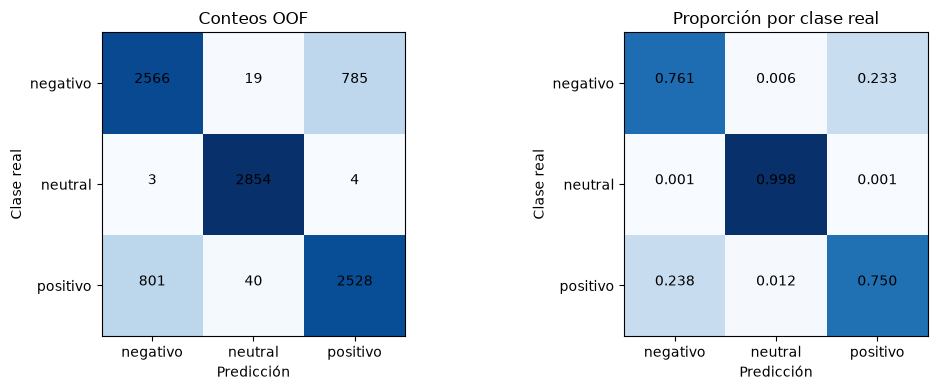

errores
label    prediction         
negativo neutral          19
         positivo        785
neutral  negativo          3
         positivo          4
positivo negativo        801
         neutral          40

**ID 2185: real positivo, predicción negativo.** Lo compré en una oferta que vi por ahí y llevo un par de meses usándolo casi todos los días en la oficina. La app del fabricante me funciona de maravilla, la uso con los ojos cerrados. Eso sí, la conexión me dio más de un dolor de cabeza, sobre todo las primeras semanas cuando intentaba vincularlo en la casa de mi hermana.

**ID 453: real negativo, predicción positivo.** Lo compré a mediados de mes y llegó en cuatro días a casa. Después de varias semanas, lo pruebo casi todos los días. Volvería a comprar el motor sin pensarlo. Ahora, la conexión se queda muy corta. Hay de todo, como se ve.

**ID 3992: real negativo, predicción positivo.** Compré este reloj el mes pasado en una tienda por internet y me llegó en tres días a casa. La app la uso todos los días antes de salir a caminar por las tardes, más que nada para revisar los pasos. La verdad sea dicha, la aplicación es óptima para el precio que tiene. Mi hermana se compró uno parecido por las mismas fechas, así que hemos comparado notas. Al final, la duración de la carga se sintió corriente en estas semanas.

**ID 3516: real negativo, predicción positivo.** Compré este aparato hace un par de meses por internet y llegó en unos cuatro días a mi casa. La app del fabricante me decepcionó de lo lindo. Lo uso a diario en la oficina y nada más. Por otro lado, el sonido me hizo la vida más fácil.

**ID 136: real positivo, predicción negativo.** Me llegó hace poco, lo pedí un martes y ya el jueves estaba en casa. Lo uso a diario, sobre todo en las mañanas. La pantalla táctil se ve deficiente para lo que cuesta. Eso sí, el peso se mantuvo comodísimo la verdad.

**ID 3292: real negativo, predicción positivo.** Lo compre hace un mes mas o menos, y desde entonces lo llevo a todas partes, a la oficina y cuando salgo el fin de semana. El envio me tardo unos cuatro dias y llego en su caja sellada. El manual de uso vale totalmente la pena, viene bien explicado. Ademas, quedé muy molesto con la velocidad, la verdad. Lo dejo a tu criterio.

In [2]:
display(pd.DataFrame(r['per_class']).T)
a=np.array(r['confusion'])
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,v,title in [(axs[0],a,'Conteos OOF'),(axs[1],a/a.sum(axis=1,keepdims=True),'Proporción por clase real')]:
    ax.imshow(v,cmap='Blues')
    ax.set(xticks=range(3),yticks=range(3),xticklabels=r['labels'],yticklabels=r['labels'],xlabel='Predicción',ylabel='Clase real',title=title)
    for i in range(3):
        for j in range(3): ax.text(j,i,str(v[i,j]) if title=='Conteos OOF' else f'{v[i,j]:.3f}',ha='center')
plt.tight_layout();plt.savefig('reports/confusion_003.png',dpi=160);plt.show()
oof=pd.read_csv('reports/predicciones_oof_003.csv',dtype={'id':str})
train=pd.read_csv('data/train.csv',dtype={'id':str})
errors=oof[oof.label.ne(oof.prediction)].merge(train[['id','text']],on='id',validate='one_to_one')
display(errors.groupby(['label','prediction']).size().rename('errores').to_frame())
for _,row in errors.sample(min(6,len(errors)),random_state=42).iterrows():
    display(Markdown(f'**ID {row.id}: real {row.label}, predicción {row.prediction}.** '+row.text))

## Producción y límites
Después de cerrar el procedimiento se reentrena la configuración elegida con todo train. El texto de eval se utiliza solo para producir las predicciones. El CSV mantiene el orden de sample_submission y no copia sus respuestas. Modelo y CSV anteriores se preservan mediante verificación de huellas.

F1 macro CV no es un puntaje de Kaggle. No se accedió a la plataforma ni se realizaron consultas o envíos. El puntaje público de la versión 003 permanece pendiente. Las plantillas o procedencias compartidas no detectadas pueden limitar la independencia de las reseñas; los grupos usados solo cubren equivalencia tras minúsculas y espacios normalizados. Una brecha pequeña tampoco descarta desplazamiento de distribución en prueba.

Para reproducir el entrenamiento desde la raíz: `.venv/bin/python -m src.experimento_003`. Para regenerar este notebook de análisis con kernel limpio: `.venv/bin/python src/notebook_003.py`. Al cargar el modelo conservar `src/features_003.py`, porque joblib utiliza esas clases de transformación.

In [3]:
display(r['checks'])
display(r['artifacts_sha256'])
s=pd.read_csv('submissions/submission_003.csv',dtype={'id':str})
display(s.head());display(s.answer.value_counts())
print('Modelo: models/modelo_003.joblib')
print('Envío para cargar manualmente: submissions/submission_003.csv')

{'csv_ids_order_schema_labels': True,
 'reload_predictions': True,
 'roundtrip_csv': True,
 'disjoint_groups': True}

{'models/modelo_003.joblib': '24ae9a37423a8ebfa94b17667b5de608054e2f55c624b63a6a7b5533fc50f510',
 'submissions/submission_003.csv': 'ac9c545d03fc95763a8492c3e52c66c31af86a7a78ba70ce770bae8fe92ccdbc'}

,id,answer
0,0,neutral
1,1,positivo
2,2,neutral
3,3,neutral
4,4,neutral


answer
positivo    1095
negativo    1063
neutral      842
Name: count, dtype: int64

Modelo: models/modelo_003.joblib
Envío para cargar manualmente: submissions/submission_003.csv
